# Video Game Sales Prediction on Steam Data
## Notebook 9 — Modification 6: The Low Group and the Breakout Group

**Motivation.** SteamSpy reports owners in ranges, and 69.7% of the games in this study sit in the lowest one,
0–20,000 owners. Notebook 8 found that this is why recent games are hard to predict: most of them share one
target value, so a regression has little to explain. This notebook takes that fact as the starting point. It
separates the games in the lowest range (the **low group**) from all others (the **breakout group**), studies
what distinguishes them, and tests whether predicting the group first gives a more reasonable prediction.

**What can and cannot be done.**
- The group of a game is not known before release; it is the outcome. The low group therefore cannot be set
  aside in advance. It can only be predicted.
- All low-group games have the same recorded value. A game with 50 owners and one with 19,000 look identical,
  so differences inside the low group cannot be studied. The comparison is low group against breakout group.

**Purpose.**

| Step | Content |
|---|---|
| Profile | How the two groups differ on the 49 pre-release variables, with release year held fixed |
| E15 | Predict the group of a game (classification) |
| Indicators | Which variables raise or lower the odds of breaking out, for paid and free-to-play games |
| E16 | Two-stage prediction: the group first, then owners among breakout games |

**Rules.**
- **Protocol:** the training set and random folds of Notebooks 5–8, and the one-year-ahead evaluation of
  Notebook 8 (each of 2022, 2023 and 2024 predicted from all earlier games). The test set is used once, for
  the classifier.
- **Adoption (E16):** the two-stage model replaces the single regression only if it raises R² (log) by at
  least 0.01 with random folds and the gain also holds one year ahead.

**Questions.**
1. What distinguishes games that rise above 20,000 owners from those that do not?
2. How well can the group be predicted before release?
3. Does predicting the group first improve the owner prediction?

The same experiments are recorded as E15 and E16 in `experiments/EXPERIMENT_LOG.md`.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, mean_absolute_error, r2_score, roc_auc_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY, PURPLE = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C", "#8172B3"
RANDOM_STATE = 42
SEEDS = [42, 1, 2, 3, 4]

FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
with open(os.path.join(DATA_DIR, "engineered_features.json")) as f:
    groups = json.load(f)
engineered = pd.read_csv(os.path.join(DATA_DIR, "engineered_features.csv.gz"))   # written by Notebook 7
data = data.merge(engineered, on="appid", how="left", validate="one_to_one")     # keeps the row order of Notebook 1

FEATURES = spec["numeric"] + spec["genres"] + spec["categories"] \
    + groups["A. Studio experience"] + groups["C. Store-page lead time"]          # the 49 variables of Notebook 7
data["owners"] = (data["owners_millions"] * 1e6).round()
data["log_owners"] = np.log1p(data["owners"])
LOW_VALUE = np.log1p(10_000)                                  # every low-group game has this target value
data["breakout"] = (data["owners"] > 10_000).astype(int)      # above the 0–20,000 owner range
data["owners_100k"] = (data["owners"] >= 100_000).astype(int)

train, test = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train))

---
# 14. Modification 6: The Low Group and the Breakout Group

## 14.1 The two groups

In [2]:
table41 = pd.DataFrame({
    "Games": [len(data), (data["breakout"] == 0).sum(), (data["breakout"] == 1).sum(), data["owners_100k"].sum()],
    "Share of all games": [1, (data["breakout"] == 0).mean(), data["breakout"].mean(), data["owners_100k"].mean()],
    "Median owners": [data["owners"].median(), 10_000, data.loc[data["breakout"] == 1, "owners"].median(),
                      data.loc[data["owners_100k"] == 1, "owners"].median()],
}, index=["All games", "Low group (0–20,000 owners)", "Breakout group (above 20,000 owners)",
          "of which 100,000 owners or more"])
by_year = data[data["release_year"] >= 2014].groupby("release_year")["breakout"].mean()
table41.to_csv(os.path.join(TAB_DIR, "table41_low_and_breakout_groups.csv"))
print("Breakout share by release year: " + " | ".join(f"{y}: {v:.0%}" for y, v in by_year.items()))
table41.style.format({"Games": "{:,}", "Share of all games": "{:.1%}", "Median owners": "{:,.0f}"}).set_caption(
    "Table 41. The low group and the breakout group")

Breakout share by release year: 2014: 80% | 2015: 63% | 2016: 51% | 2017: 36% | 2018: 29% | 2019: 25% | 2020: 28% | 2021: 28% | 2022: 24% | 2023: 20% | 2024: 15%


,Games,Share of all games,Median owners
All games,"76,727",100.0%,"10,000"
"Low group (0–20,000 owners)","53,446",69.7%,"10,000"
"Breakout group (above 20,000 owners)","23,281",30.3%,"75,000"
"of which 100,000 owners or more","8,194",10.7%,"350,000"


**Interpretation.**
- **The low group holds 53,446 games (69.7%) and the breakout group 23,281 (30.3%).** The median breakout game
  has 75,000 owners, and 8,194 games (10.7%) reach 100,000 or more.
- **The breakout share depends strongly on release year.** It falls from 80% for 2014 releases to 15% for 2024
  releases, mostly because older games have had longer to sell (Notebook 8). Any comparison of the two groups
  must hold release year fixed, or "being old" would appear as the main success factor.

## 14.2 How the groups differ

Each of the 48 variables other than release year is compared between the groups. Low-group games are
reweighted so that both groups have the same mix of release years. The standardised difference is the gap
between the two means in standard deviations, which puts all variables on one scale.

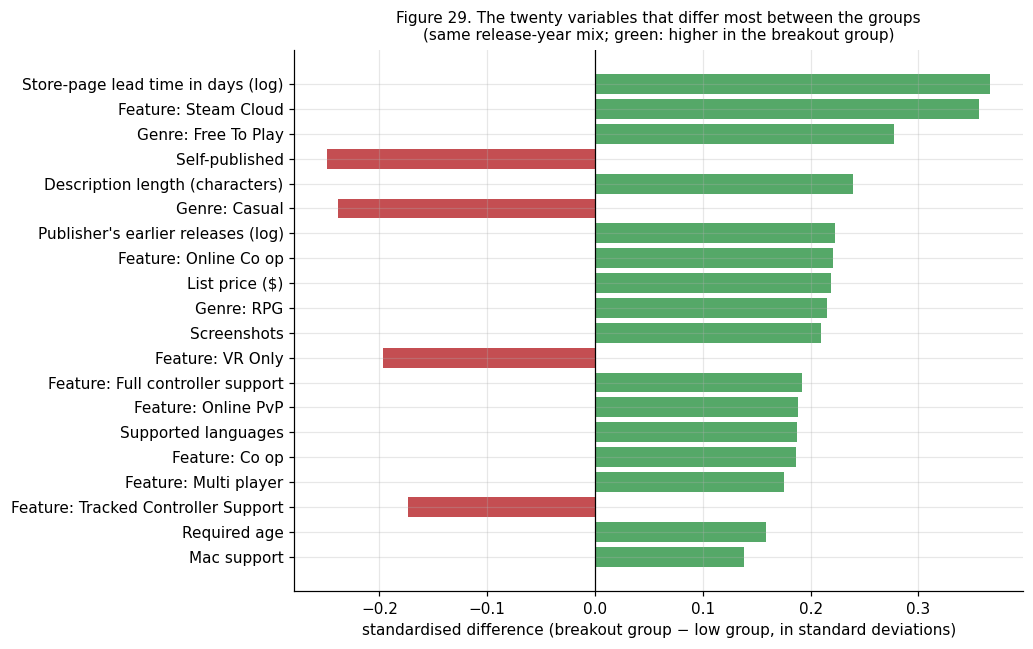

,Breakout group,"Low group, same release-year mix","Low group, unadjusted",Standardised difference
Variable,,,,
Store-page lead time in days (log),4.14,3.35,3.61,0.37
Feature: Steam Cloud,0.38,0.22,0.21,0.36
Genre: Free To Play,0.11,0.04,0.04,0.28
Self-published,0.57,0.69,0.73,-0.25
Description length (characters),1510.73,1227.61,1205.95,0.24
Genre: Casual,0.33,0.45,0.47,-0.24
Publisher's earlier releases (log),1.14,0.84,0.87,0.22
Feature: Online Co op,0.09,0.03,0.04,0.22
List price ($),9.87,7.38,7.27,0.22


In [3]:
NAMES = {
    "price": "List price ($)", "required_age": "Required age", "n_languages": "Supported languages",
    "n_audio_languages": "Full-audio languages", "mac": "Mac support", "linux": "Linux support",
    "n_screenshots": "Screenshots", "description_length": "Description length (characters)",
    "log_dev_prior_releases": "Developer's earlier releases (log)", "log_pub_prior_releases": "Publisher's earlier releases (log)",
    "dev_debut": "Developer's first game", "self_published": "Self-published", "n_developers": "Number of developers",
    "log_lead_days": "Store-page lead time in days (log)", "lead_missing": "Lead time missing",
}


def label(v):
    if v.startswith("genre_"):
        return "Genre: " + v[6:].replace("_", " ")
    if v.startswith("cat_"):
        return "Feature: " + v[4:].replace("_", " ")
    return NAMES.get(v, v)


# Low-group games are reweighted so that both groups have the same mix of release years
low, high = data[data["breakout"] == 0], data[data["breakout"] == 1]
weights = low["release_year"].map(high["release_year"].value_counts() / low["release_year"].value_counts()).fillna(0)
rows = []
for v in [c for c in FEATURES if c != "release_year"]:
    mean_high, mean_low_raw = high[v].mean(), low[v].mean()
    mean_low = np.average(low[v], weights=weights)
    sd = np.sqrt((high[v].var() + np.average((low[v] - mean_low) ** 2, weights=weights)) / 2)
    rows.append({"Variable": label(v), "Breakout group": mean_high, "Low group, same release-year mix": mean_low,
                 "Low group, unadjusted": mean_low_raw, "Standardised difference": (mean_high - mean_low) / sd})
profile = pd.DataFrame(rows).set_index("Variable")
profile = profile.reindex(profile["Standardised difference"].abs().sort_values(ascending=False).index)
profile.to_csv(os.path.join(TAB_DIR, "table42_low_vs_breakout_profile.csv"))
table42 = profile.head(20)

fig, ax = plt.subplots(figsize=(9.5, 6))
t = table42.iloc[::-1]
ax.barh(t.index, t["Standardised difference"], color=[GREEN if d > 0 else RED for d in t["Standardised difference"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("standardised difference (breakout group − low group, in standard deviations)")
ax.set_title("Figure 29. The twenty variables that differ most between the groups\n"
             "(same release-year mix; green: higher in the breakout group)", fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig29_low_vs_breakout_profile.png"), dpi=150, bbox_inches="tight")
plt.show()
table42.style.format("{:.2f}").set_caption(
    "Table 42. Means of the twenty variables that differ most (yes/no variables: share of games; all 48 are in the CSV file)")

**Interpretation.** Compared with low-group games of the same release years, breakout games:
- **were on the store longer before release.** Their typical lead time is about 62 days against 27 (the means
  of log days, 4.14 and 3.35, converted back). This is the largest difference.
- **more often have a separate publisher.** 57.4% are self-published, against 69.2% of the low group.
- **cost more and are more often free-to-play.** The mean list price is \$9.87 against \$7.38, and 10.6% are
  free-to-play against 3.6%.
- **have fuller store pages and wider localisation:** descriptions of 1,511 characters against 1,228, 10.1
  screenshots against 8.8, and 5.5 supported languages against 3.7.
- **offer more online play:** online co-op in 8.7% against 3.4%, online PvP in 11.2% against 6.0%.
- **are more often RPGs** (22.9% against 14.6%) **and less often Casual** (33.1% against 44.7%) **or VR-only**
  (3.3% against 7.8%).

**Two cautions.**
- **No single variable separates the groups.** The largest standardised difference is 0.37 standard deviations,
  so the two groups overlap heavily on every variable. A low-group game is not recognisable by one indicator.
- **Steam Cloud ranks second (38.2% against 22.1%), but it may partly be a result of success.** Store pages are
  read in 2025, and a developer can add cloud saves after a game has found an audience.

## 14.3 Predicting the group (E15)

A Gradient Boosting classifier (default settings) and a Logistic Regression are fitted on the 49 variables to
predict whether a game rises above 20,000 owners. The regression model of Notebook 7 is added as a reference:
its predicted owners are used only to rank games. The same is repeated for 100,000 owners or more.

**Measures.**
- **ROC-AUC:** the chance that a randomly chosen breakout game is ranked above a randomly chosen low-group
  game (0.5 = random, 1 = perfect).
- **Within-year ROC-AUC:** the same, computed inside each release year and averaged. It removes the advantage
  of simply ranking older games higher.
- **Precision in top 10%:** among the tenth of each year's games that the model ranks highest, the share that
  really broke out. The base rate is what random picking would give.
- **Brier score:** mean squared error of the predicted probabilities (lower is better).

In [4]:
def gb_classifier(seed=RANDOM_STATE):
    return HistGradientBoostingClassifier(random_state=seed)


def gb_regressor(seed=RANDOM_STATE):
    return HistGradientBoostingRegressor(random_state=seed)


def logistic():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))


def out_of_fold(make_model, target, probability=True):
    """Out-of-fold predictions on the training set with the random folds of Notebooks 5–8."""
    oof = np.zeros(len(train))
    for tr, va in folds:
        m = make_model().fit(train.iloc[tr][FEATURES], train[target].to_numpy()[tr])
        X_va = train.iloc[va][FEATURES]
        oof[va] = m.predict_proba(X_va)[:, 1] if probability else m.predict(X_va)
    return oof


def within_year_auc(y, score, year):
    """ROC-AUC computed inside each release year (years with 200+ games), averaged with the games as weights.
    It asks whether the model ranks a year's breakout games above that year's other games."""
    values, sizes = [], []
    for v in np.unique(year):
        m = year == v
        if m.sum() >= 200 and 0 < y[m].mean() < 1:
            values.append(roc_auc_score(y[m], score[m]))
            sizes.append(m.sum())
    return float(np.average(values, weights=sizes))


def top_decile_precision(y, score, year):
    """Share of true positives among the 10% of each release year's games with the highest scores."""
    hits = picked = 0
    for v in np.unique(year):
        idx = np.where(year == v)[0]
        if len(idx) >= 200:
            k = int(round(0.1 * len(idx)))
            hits += y[idx[np.argsort(-score[idx])[:k]]].sum()
            picked += k
    return hits / picked


def classification_scores(y, score, year, probability=True):
    return {"Base rate": y.mean(), "ROC-AUC": roc_auc_score(y, score),
            "Within-year ROC-AUC": within_year_auc(y, score, year),
            "Precision in top 10%": top_decile_precision(y, score, year),
            "Brier score": brier_score_loss(y, score) if probability else np.nan}

In [5]:
year_train = train["release_year"].to_numpy()
regression_oof = out_of_fold(gb_regressor, "log_owners", probability=False)   # the reference model of Notebook 7
oof = {}
rows = []
for target, name in [("breakout", "Above 20,000 owners"), ("owners_100k", "100,000 owners or more")]:
    y = train[target].to_numpy()
    oof[target] = out_of_fold(gb_classifier, target)
    for model, score, probability in [("Gradient Boosting classifier", oof[target], True),
                                      ("Logistic Regression", out_of_fold(logistic, target), True),
                                      ("Regression model of Notebook 7, used to rank", regression_oof, False)]:
        rows.append({"Outcome": name, "Model": model, "Scored on": "Training set, random folds",
                     **classification_scores(y, score, year_train, probability)})
fitted_classifier = gb_classifier().fit(train[FEATURES], train["breakout"])
test_probability = fitted_classifier.predict_proba(test[FEATURES])[:, 1]      # the test set is used once
rows.append({"Outcome": "Above 20,000 owners", "Model": "Gradient Boosting classifier", "Scored on": "Test set",
             **classification_scores(test["breakout"].to_numpy(), test_probability, test["release_year"].to_numpy())})
table43 = pd.DataFrame(rows).set_index(["Outcome", "Model", "Scored on"])
table43.to_csv(os.path.join(TAB_DIR, "table43_breakout_classifier.csv"))
table43.style.format({"Base rate": "{:.1%}", "ROC-AUC": "{:.3f}", "Within-year ROC-AUC": "{:.3f}",
                      "Precision in top 10%": "{:.1%}", "Brier score": "{:.3f}"}, na_rep="").set_caption(
    "Table 43. Predicting the group of a game (E15)")

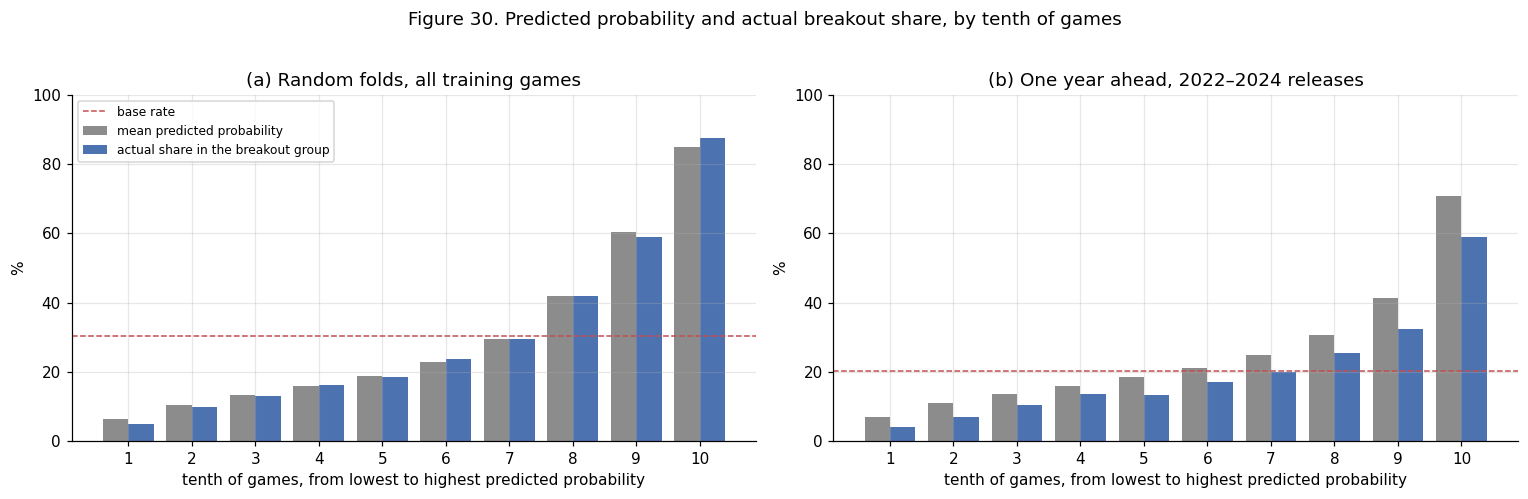

,Games,Base rate,ROC-AUC,Precision in top 10%,Lift over base rate,Mean predicted probability
Release year,,,,,,
2022,"8,062",24.3%,0.714,62.0%,2.6×,28.4%
2023,"9,251",19.5%,0.751,59.9%,3.1×,26.2%
2024,"5,618",15.5%,0.754,51.1%,3.3×,20.2%


In [6]:
rows, ahead = [], []
for year in (2022, 2023, 2024):
    earlier, target = train[train["release_year"] < year], train[train["release_year"] == year]
    y = target["breakout"].to_numpy()
    p = gb_classifier().fit(earlier[FEATURES], earlier["breakout"]).predict_proba(target[FEATURES])[:, 1]
    k = int(round(0.1 * len(target)))
    precision = y[np.argsort(-p)[:k]].mean()
    rows.append({"Release year": year, "Games": len(target), "Base rate": y.mean(), "ROC-AUC": roc_auc_score(y, p),
                 "Precision in top 10%": precision, "Lift over base rate": precision / y.mean(),
                 "Mean predicted probability": p.mean()})
    ahead.append(pd.DataFrame({"p": p, "y": y}))
ahead = pd.concat(ahead)
table44 = pd.DataFrame(rows).set_index("Release year")
table44.to_csv(os.path.join(TAB_DIR, "table44_breakout_one_year_ahead.csv"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, frame, title in [(axes[0], pd.DataFrame({"p": oof["breakout"], "y": train["breakout"]}), "(a) Random folds, all training games"),
                         (axes[1], ahead, "(b) One year ahead, 2022–2024 releases")]:
    deciles = frame.groupby(pd.qcut(frame["p"], 10, labels=False)).mean()
    x = np.arange(1, 11)
    ax.bar(x - 0.2, 100 * deciles["p"], 0.4, color=GREY, label="mean predicted probability")
    ax.bar(x + 0.2, 100 * deciles["y"], 0.4, color=BLUE, label="actual share in the breakout group")
    ax.axhline(100 * frame["y"].mean(), color=RED, ls="--", lw=1, label="base rate")
    ax.set_xticks(x)
    ax.set_xlabel("tenth of games, from lowest to highest predicted probability")
    ax.set_ylabel("%")
    ax.set_ylim(0, 100)
    ax.set_title(title)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Figure 30. Predicted probability and actual breakout share, by tenth of games", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig30_breakout_by_decile.png"), dpi=150, bbox_inches="tight")
plt.show()
table44.style.format({"Games": "{:,}", "Base rate": "{:.1%}", "ROC-AUC": "{:.3f}", "Precision in top 10%": "{:.1%}",
                      "Lift over base rate": "{:.1f}×", "Mean predicted probability": "{:.1%}"}).set_caption(
    "Table 44. Gradient Boosting classifier, each year predicted from all earlier training-set games")

**Interpretation.**
- **The group can be predicted well above chance, but far from perfectly.** With random folds the Gradient
  Boosting classifier reaches ROC-AUC 0.805, and 0.755 inside release years. The test set gives the same
  picture (0.801 and 0.753).
- **The top of the ranking is where the model is useful.** Among the tenth of each year's games it ranks
  highest, 72.7% broke out, against a base rate of 30.5%.
- **Classification is not more accurate than the regression; it is a different way to report it.** Ranking
  games by the predicted owners of Notebook 7's regression gives nearly the same ROC-AUC (0.798) and top-10%
  precision (72.1%). Logistic Regression is clearly weaker (0.767).
- **For 100,000 owners or more the ranking is sharper** (ROC-AUC 0.886, within years 0.851), but the outcome is
  rarer: 45.3% of the top tenth reach it, against a base rate of 10.7%.
- **One year ahead the model still ranks well (Table 44).** ROC-AUC is 0.714, 0.751 and 0.754 for 2022, 2023 and
  2024. In the top tenth, 62.0%, 59.9% and 51.1% broke out, which is 2.6 to 3.3 times the base rate of each
  year.
- **Its probabilities are too high for later years (Figure 30b).** The mean predicted probability is 28.4%,
  26.2% and 20.2%, against actual shares of 24.3%, 19.5% and 15.5%. With random folds the probabilities match
  the actual shares closely (Figure 30a). This is the level error of Notebook 8 again: a model trained on older
  games expects more breakouts than recent years produce.

## 14.4 Indicators: what raises or lowers the odds of breaking out

**Odds ratios.** A logistic regression is fitted separately for paid and free-to-play games, with the variables
of Notebooks 6 and 7 in the same banded form and release-year indicators as controls. Each coefficient is
reported as the percentage change in the odds of being in the breakout group, other variables held fixed. As
in Notebook 6, these models describe the data and use all games.

**Permutation importance.** For the Gradient Boosting classifier, the drop in ROC-AUC on the validation folds
when all variables of a group are shuffled together.

Paid: 68,380 games, 28.8% in the breakout group, 56 variables of which 18 release-year indicators
Free-to-play: 8,347 games, 42.6% in the breakout group, 44 variables of which 12 release-year indicators


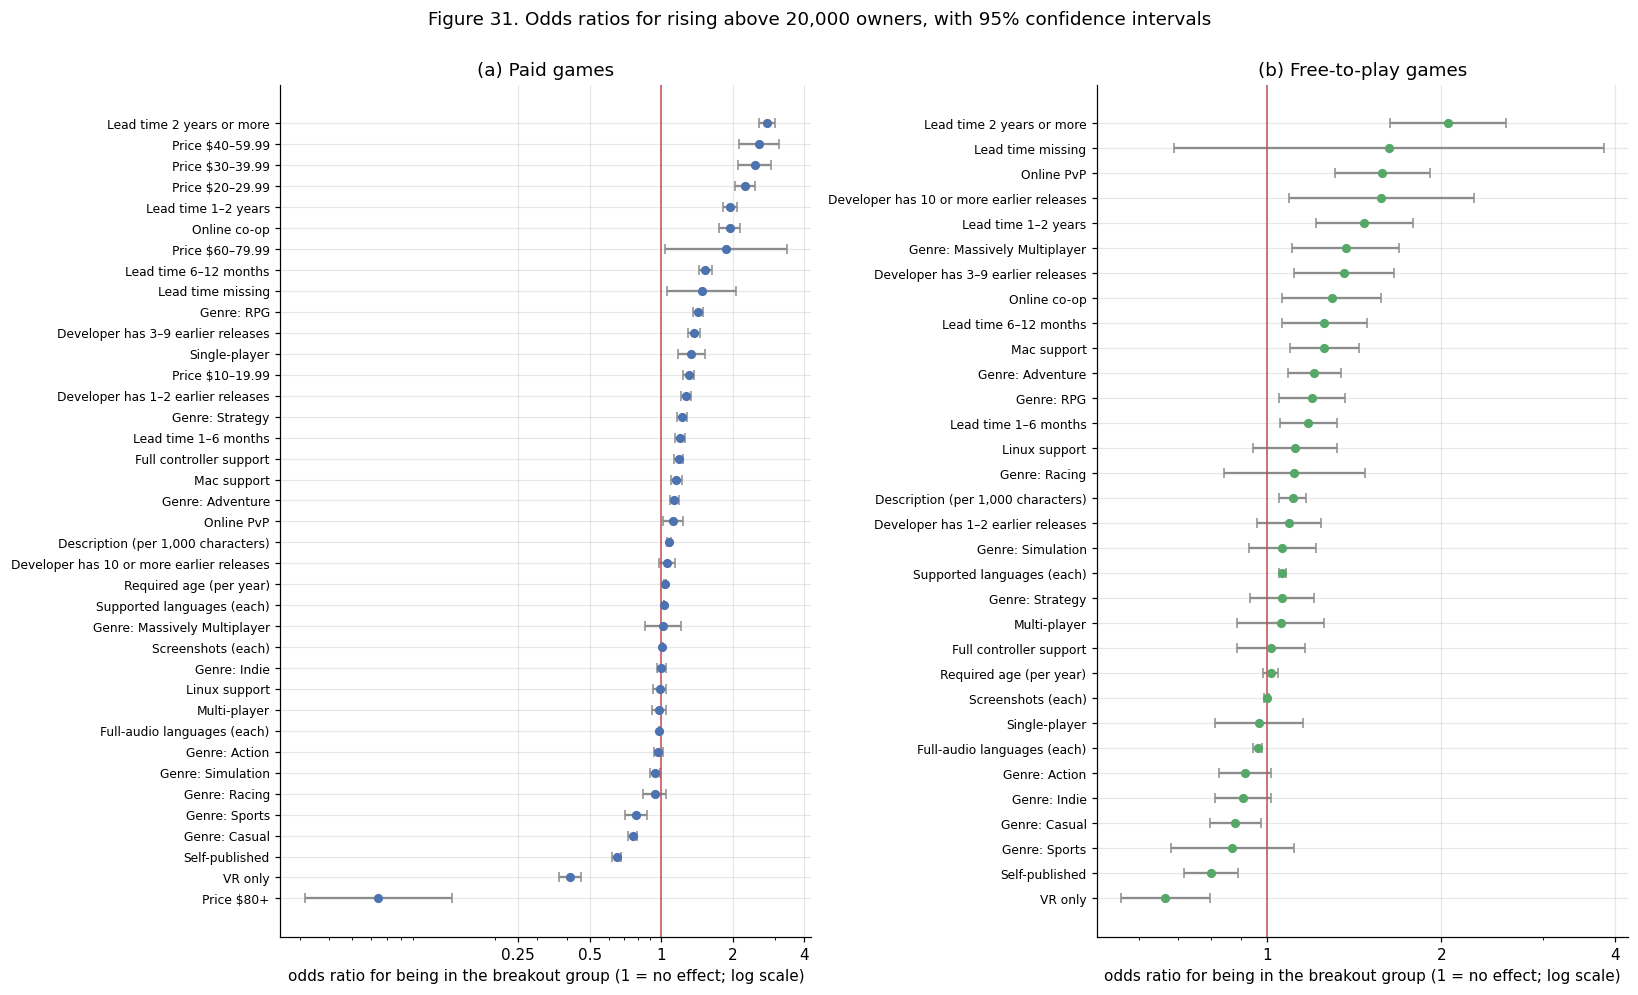

,Paid: effect on odds [95% CI],Paid: p,Free-to-play: effect on odds [95% CI],Free-to-play: p
Variable,,,,
Price $10–19.99,"+30% [+24, +37]",<0.001,—,—
Price $20–29.99,"+125% [+104, +147]",<0.001,—,—
Price $30–39.99,"+147% [+110, +191]",<0.001,—,—
Price $40–59.99,"+159% [+113, +215]",<0.001,—,—
Price $60–79.99,"+87% [+3, +239]",0.038,—,—
Price $80+,"-94% [-97, -87]",<0.001,—,—
Developer has 1–2 earlier releases,"+28% [+22, +34]",<0.001,"+9% [-4, +24]",0.176
Developer has 3–9 earlier releases,"+37% [+29, +45]",<0.001,"+36% [+11, +66]",0.003
Developer has 10 or more earlier releases,"+6% [-2, +14]",0.144,"+58% [+9, +127]",0.015


In [7]:
def logit(frame, columns, outcome="breakout"):
    """Logistic regression by Newton's method. Coefficients are converted to percentage changes in the odds,
    100 × (exp(b) − 1), with 95% confidence intervals and two-sided p-values."""
    X = np.column_stack([np.ones(len(frame))] + [frame[c].astype(float).to_numpy() for c in columns])
    y = frame[outcome].to_numpy(dtype=float)
    beta = np.zeros(X.shape[1])
    for _ in range(100):
        p = 1 / (1 + np.exp(-X @ beta))
        hessian = X.T @ (X * (p * (1 - p))[:, None]) + 1e-8 * np.eye(X.shape[1])
        step = np.linalg.solve(hessian, X.T @ (y - p))
        beta += step
        if np.abs(step).max() < 1e-8:
            break
    se = np.sqrt(np.diag(np.linalg.inv(hessian)))
    out = pd.DataFrame({"variable": ["(intercept)"] + list(columns), "coef": beta,
                        "p_value": 2 * stats.norm.sf(np.abs(beta / se))}).set_index("variable")
    out["effect on odds (%)"] = 100 * (np.exp(out["coef"]) - 1)
    out["CI low (%)"] = 100 * (np.exp(out["coef"] - 1.96 * se) - 1)
    out["CI high (%)"] = 100 * (np.exp(out["coef"] + 1.96 * se) - 1)
    return out


# The variables of Notebooks 6 and 7, in the same banded form
GENRES = ["genre_Action", "genre_Adventure", "genre_RPG", "genre_Simulation", "genre_Strategy",
          "genre_Sports", "genre_Casual", "genre_Indie", "genre_Massively_Multiplayer", "genre_Racing"]
STORE_PAGE = ["n_languages", "n_audio_languages", "n_screenshots", "description_length_1000"]
PLATFORM_PLAY = ["mac", "linux", "required_age", "cat_Single_player", "cat_Multi_player", "cat_Online_PvP",
                 "cat_Online_Co_op", "cat_Full_controller_support", "cat_VR_Only"]
BAND_EDGES = [0.0, 10, 20, 30, 40, 60, 80, np.inf]
BAND_LABELS = ["$0.99–9.99", "$10–19.99", "$20–29.99", "$30–39.99", "$40–59.99", "$60–79.99", "$80+"]

frame = data.copy()
frame["description_length_1000"] = frame["description_length"] / 1000
price_band = pd.cut(frame["price"], BAND_EDGES, labels=BAND_LABELS, right=False)
PRICE = [f"Price {b}" for b in BAND_LABELS[1:]]
for b in BAND_LABELS[1:]:
    frame[f"Price {b}"] = ((price_band == b) & (frame["price"] > 0)).astype(int)
lead = frame["lead_days"].where(frame["lead_missing"] == 0)
STUDIO_LEAD = {
    "Developer has 1–2 earlier releases": frame["dev_prior_releases"].between(1, 2),
    "Developer has 3–9 earlier releases": frame["dev_prior_releases"].between(3, 9),
    "Developer has 10 or more earlier releases": frame["dev_prior_releases"] >= 10,
    "Self-published": frame["self_published"] == 1,
    "Lead time 1–6 months": lead.between(30, 182), "Lead time 6–12 months": lead.between(183, 364),
    "Lead time 1–2 years": lead.between(365, 729), "Lead time 2 years or more": lead >= 730,
    "Lead time missing": frame["lead_missing"] == 1,
}
for name, flag in STUDIO_LEAD.items():
    frame[name] = flag.astype(int)
ODDS_NAMES = {"n_languages": "Supported languages (each)", "n_audio_languages": "Full-audio languages (each)",
              "n_screenshots": "Screenshots (each)", "description_length_1000": "Description (per 1,000 characters)",
              "mac": "Mac support", "linux": "Linux support", "required_age": "Required age (per year)",
              "cat_Single_player": "Single-player", "cat_Multi_player": "Multi-player", "cat_Online_PvP": "Online PvP",
              "cat_Online_Co_op": "Online co-op", "cat_Full_controller_support": "Full controller support",
              "cat_VR_Only": "VR only"}


def odds_label(v):
    return "Genre: " + v[6:].replace("_", " ") if v.startswith("genre_") else ODDS_NAMES.get(v, v)


odds = {}
for seg, part in [("Paid", frame[frame["price"] > 0]), ("Free-to-play", frame[frame["price"] == 0])]:
    years = pd.DataFrame({f"year_{y}": (part["release_year"] == y).astype(int)
                          for y in sorted(part["release_year"].unique())
                          if y != 2020 and (part["release_year"] == y).sum() >= 30}, index=part.index)
    part = pd.concat([part, years], axis=1)
    columns = (PRICE if seg == "Paid" else []) + list(STUDIO_LEAD) + [g for g in GENRES if part[g].sum() >= 30] \
        + STORE_PAGE + PLATFORM_PLAY + list(years.columns)
    odds[seg] = logit(part, columns)
    print(f"{seg}: {len(part):,} games, {part['breakout'].mean():.1%} in the breakout group, {len(columns)} variables "
          f"of which {len(years.columns)} release-year indicators")

shown = [v for v in odds["Paid"].index if v != "(intercept)" and not v.startswith("year_")]
rows = []
for v in shown:
    row = {"Variable": odds_label(v)}
    for seg in ["Paid", "Free-to-play"]:
        if v in odds[seg].index:
            r = odds[seg].loc[v]
            row[f"{seg}: effect on odds [95% CI]"] = f"{r['effect on odds (%)']:+.0f}% [{r['CI low (%)']:+.0f}, {r['CI high (%)']:+.0f}]"
            row[f"{seg}: p"] = "<0.001" if r["p_value"] < 0.001 else f"{r['p_value']:.3f}"
        else:
            row[f"{seg}: effect on odds [95% CI]"], row[f"{seg}: p"] = "—", "—"
    rows.append(row)
table45 = pd.DataFrame(rows).set_index("Variable")
pd.concat([odds[s].assign(segment=s) for s in odds]).to_csv(os.path.join(TAB_DIR, "table45_breakout_odds.csv"))

fig, axes = plt.subplots(1, 2, figsize=(15, 9))
for ax, seg, color in [(axes[0], "Paid", BLUE), (axes[1], "Free-to-play", GREEN)]:
    t = odds[seg].loc[[v for v in shown if v in odds[seg].index]].copy()
    t["ratio"] = np.exp(t["coef"])
    t = t.sort_values("ratio")
    ypos = np.arange(len(t))
    lo, hi = 1 + t["CI low (%)"] / 100, 1 + t["CI high (%)"] / 100
    ax.errorbar(t["ratio"], ypos, xerr=[t["ratio"] - lo, hi - t["ratio"]], fmt="o", color=color, ecolor=GREY,
                capsize=3, markersize=5)
    ax.axvline(1, color=RED, lw=1)
    ax.set_yticks(ypos)
    ax.set_yticklabels([odds_label(v) for v in t.index], fontsize=8)
    ax.set_xscale("log")
    left, right = ax.get_xlim()
    ticks = [x for x in [0.25, 0.5, 1, 2, 4, 8, 16] if left <= x <= right]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{x:g}" for x in ticks])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("odds ratio for being in the breakout group (1 = no effect; log scale)")
    ax.set_title(f"({'a' if seg == 'Paid' else 'b'}) {seg} games")
fig.suptitle("Figure 31. Odds ratios for rising above 20,000 owners, with 95% confidence intervals", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig31_breakout_odds.png"), dpi=150, bbox_inches="tight")
plt.show()
table45.style.set_caption("Table 45. Percentage change in the odds of rising above 20,000 owners (logistic regression "
                          "with release-year controls; price relative to $0.99–9.99, developer relative to a first "
                          "game, lead time relative to under 1 month)")

In [8]:
FEATURE_GROUPS = {
    "Price / business model": ["price", "genre_Free_To_Play"],
    "Release year": ["release_year"],
    "Localisation": ["n_languages", "n_audio_languages"],
    "Platform support (Mac/Linux)": ["mac", "linux"],
    "Store-page presentation": ["n_screenshots", "description_length"],
    "Age rating & content descriptors": ["required_age", "genre_Violent", "genre_Gore", "genre_Nudity"],
    "Game genres": ["genre_Indie", "genre_Casual", "genre_Action", "genre_Adventure", "genre_Simulation",
                    "genre_Strategy", "genre_RPG", "genre_Sports", "genre_Racing", "genre_Massively_Multiplayer",
                    "genre_Education"],
    "Play mode (single/multiplayer)": ["cat_Single_player", "cat_Multi_player", "cat_PvP", "cat_Co_op",
                                       "cat_Online_PvP", "cat_Online_Co_op", "cat_Shared_Split_Screen",
                                       "cat_Shared_Split_Screen_PvP", "cat_Shared_Split_Screen_Co_op"],
    "Controller & VR support": ["cat_Full_controller_support", "cat_Partial_Controller_Support",
                                "cat_Tracked_Controller_Support", "cat_VR_Only"],
    "Steam platform features": ["cat_Steam_Cloud", "cat_Steam_Leaderboards", "cat_Stats",
                                "cat_Includes_level_editor", "cat_Captions_available"],
    "Studio experience": groups["A. Studio experience"],
    "Store-page lead time": groups["C. Store-page lead time"],
}
assert sorted(c for cols in FEATURE_GROUPS.values() for c in cols) == sorted(FEATURES)

drops = {g: [] for g in FEATURE_GROUPS}
y_breakout = train["breakout"].to_numpy()
for i, (tr, va) in enumerate(folds):
    m = gb_classifier().fit(train.iloc[tr][FEATURES], y_breakout[tr])
    X_va = train.iloc[va][FEATURES]
    base_auc = roc_auc_score(y_breakout[va], m.predict_proba(X_va)[:, 1])
    rng = np.random.default_rng(RANDOM_STATE + i)
    for g, cols in FEATURE_GROUPS.items():
        for _ in range(5):
            shuffled = X_va.copy()
            shuffled[cols] = shuffled[cols].to_numpy()[rng.permutation(len(shuffled))]
            drops[g].append(base_auc - roc_auc_score(y_breakout[va], m.predict_proba(shuffled)[:, 1]))
table46 = pd.DataFrame({"Variables": {g: len(c) for g, c in FEATURE_GROUPS.items()},
                        "Drop in ROC-AUC when shuffled": {g: np.mean(d) for g, d in drops.items()},
                        "SD": {g: np.std(d, ddof=1) for g, d in drops.items()}})
table46 = table46.sort_values("Drop in ROC-AUC when shuffled", ascending=False)
table46.index.name = "Variable group"
table46.to_csv(os.path.join(TAB_DIR, "table46_breakout_importance.csv"))
table46.style.format({"Drop in ROC-AUC when shuffled": "{:.3f}", "SD": "{:.3f}"}).set_caption(
    "Table 46. Permutation importance by variable group, Gradient Boosting classifier (validation folds, 5 repeats each)")

,Variables,Drop in ROC-AUC when shuffled,SD
Variable group,,,
Release year,1,0.129,0.005
Price / business model,2,0.035,0.003
Localisation,2,0.024,0.002
Game genres,11,0.021,0.001
Store-page lead time,2,0.017,0.003
Studio experience,5,0.016,0.002
Steam platform features,5,0.008,0.001
Store-page presentation,2,0.006,0.001
Controller & VR support,4,0.006,0.001


**Interpretation.** Each effect is the change in the odds of rising above 20,000 owners, with the other
variables and release year held fixed.
- **Paid games (Figure 31a).**
  - **Raise the odds most:** a store page online two years or more (+180% against under a month), a price of
    \$20–59.99 (+125% to +159% against \$0.99–9.99), online co-op (+94%), RPG (+42%), a developer with 3–9
    earlier releases (+37%) and single-player mode (+34%).
  - **Lower the odds most:** a price of \$80 or more (−94%), VR only (−59%), self-published (−35%), Casual
    (−24%) and Sports (−22%).
- **Free-to-play games (Figure 31b).**
  - **Raise the odds most:** a store page online two years or more (+106%), online PvP (+58%), a developer with
    10 or more earlier releases (+58%) and Massively Multiplayer (+37%).
  - **Lower the odds most:** VR only (−33%) and self-published (−20%).
- **The segments differ as in Notebooks 6 and 7.** Each supported language adds 6.2% to the odds for
  free-to-play games and 2.8% for paid games. A developer with many earlier releases helps free-to-play games
  (+58%) but not paid games (+6%, not significant).
- **Release year is again the most important variable for the classifier (Table 46)**, with a drop in ROC-AUC
  of 0.129 when shuffled. Price and business model (0.035), localisation (0.024) and genres (0.021) follow,
  then store-page lead time and studio experience (0.017 each).

**What this says about low-group games.** The typical low-group game is a cheap, self-published title that
appeared on the store shortly before release, with a short page, few languages and no online play. These are
associations, not causes. They mostly describe small productions, and the data do not show budget, marketing
or quality. Giving a small game a long lead time or a higher price would not by itself move it out of the low
group.

## 14.5 Two-stage prediction (E16)

The single regression of Notebook 7 predicts log owners for every game with one model. The two-stage model
splits the task:
- **Stage 1:** the probability *p* that the game is in the breakout group (the classifier of Section 14.3).
- **Stage 2:** a regression of log owners fitted on breakout games only.

Two ways of combining them are compared:
- **Expected value:** *p* × (stage-2 prediction) + (1 − *p*) × (the low-group value).
- **Cut at 50%:** the stage-2 prediction if *p* is at least 0.5, otherwise the low-group value.

"Correct side of 20,000" is the share of games whose predicted owners fall on the same side of 20,000 as their
actual owners. Predicting the low group for every game is added as the simplest possible baseline.

In [9]:
def two_stage(fit_frame, score_frame, seed=RANDOM_STATE):
    """Stage 1: probability of being in the breakout group. Stage 2: log owners, fitted on breakout games only.
    Returns the stage-1 probability and the stage-2 prediction for every game in `score_frame`."""
    p = gb_classifier(seed).fit(fit_frame[FEATURES], fit_frame["breakout"]).predict_proba(score_frame[FEATURES])[:, 1]
    above = fit_frame[fit_frame["breakout"] == 1]
    return p, gb_regressor(seed).fit(above[FEATURES], above["log_owners"]).predict(score_frame[FEATURES])


def combine(p, stage2, how):
    if how == "expected":                       # probability-weighted mean of the two outcomes
        return p * stage2 + (1 - p) * LOW_VALUE
    return np.where(p >= 0.5, stage2, LOW_VALUE)  # "cut": the low value unless breakout is more likely than not


def regression_scores(frame, pred):
    y = frame["log_owners"].to_numpy()
    return {"R² (log)": r2_score(y, pred), "MAE (log)": mean_absolute_error(y, pred),
            "Correct side of 20,000 owners": float(np.mean((pred > np.log1p(20_000)) == (frame["breakout"] == 1)))}


# Random folds
p_oof, stage2_oof = np.zeros(len(train)), np.zeros(len(train))
for tr, va in folds:
    p_oof[va], stage2_oof[va] = two_stage(train.iloc[tr], train.iloc[va])
MODELS = {"Always the low group": np.full(len(train), LOW_VALUE),
          "Single regression (Notebook 7)": regression_oof,
          "E16: two-stage, expected value": combine(p_oof, stage2_oof, "expected"),
          "E16: two-stage, cut at 50%": combine(p_oof, stage2_oof, "cut")}
random_scores = {name: regression_scores(train, pred) for name, pred in MODELS.items()}

# One year ahead (2022, 2023, 2024 from earlier years), averaged over years and five seeds
ahead_scores = {name: [] for name in MODELS}
for year in (2022, 2023, 2024):
    earlier, target = train[train["release_year"] < year], train[train["release_year"] == year]
    for seed in SEEDS:
        single = gb_regressor(seed).fit(earlier[FEATURES], earlier["log_owners"]).predict(target[FEATURES])
        p, stage2 = two_stage(earlier, target, seed)
        for name, pred in zip(MODELS, [np.full(len(target), LOW_VALUE), single, combine(p, stage2, "expected"),
                                           combine(p, stage2, "cut")]):
            ahead_scores[name].append(regression_scores(target, pred))

rows = []
for name in MODELS:
    a = pd.DataFrame(ahead_scores[name]).mean()
    rows.append({"Model": name, "Random folds: R² (log)": random_scores[name]["R² (log)"],
                 "Random folds: MAE (log)": random_scores[name]["MAE (log)"],
                 "Random folds: correct side of 20,000": random_scores[name]["Correct side of 20,000 owners"],
                 "One year ahead: R² (log)": a["R² (log)"], "One year ahead: MAE (log)": a["MAE (log)"],
                 "One year ahead: correct side of 20,000": a["Correct side of 20,000 owners"]})
table47 = pd.DataFrame(rows).set_index("Model")
table47.to_csv(os.path.join(TAB_DIR, "table47_two_stage.csv"))
table47.style.format({c: ("{:.1%}" if "correct side" in c else "{:.3f}") for c in table47.columns}).set_caption(
    "Table 47. Single regression against the two-stage model (one year ahead: mean of 2022–2024 and five seeds)")

,Random folds: R² (log),Random folds: MAE (log),"Random folds: correct side of 20,000",One year ahead: R² (log),One year ahead: MAE (log),"One year ahead: correct side of 20,000"
Model,,,,,,
Always the low group,-0.306,0.687,69.5%,-0.184,0.399,80.2%
Single regression (Notebook 7),0.460,0.634,77.2%,0.250,0.556,78.7%
"E16: two-stage, expected value",0.461,0.632,77.6%,0.265,0.552,79.4%
"E16: two-stage, cut at 50%",0.308,0.530,78.8%,0.027,0.400,81.9%


**Interpretation.**
- **The two-stage model with the expected value matches the single regression with random folds.** R² (log) is
  0.461 against 0.460 (+0.001), far below the 0.01 needed. One year ahead it is 0.265 against 0.250 (+0.015).
  The gain does not appear with random folds, so the model is **not adopted**.
- **The cut at 50% trades one error for another.** It lowers the mean absolute error (0.531 against 0.634)
  because it gives most games exactly the low-group value, which is correct for 70% of them. Its R² falls to
  0.308, because every breakout game it misses is now far off.
- **For recent games, a yes/no call hardly beats the simplest baseline.** One year ahead, calling every game
  low is right for 80.2% of games. The single regression is on the correct side of 20,000 for 78.7%, slightly
  worse than that baseline, and the cut model for 81.9%, only 1.7 points better. The baseline's mean absolute
  error (0.399) also equals the cut model's (0.400).
- **The value of the model is in ranking, not in a point prediction.** No model here says reliably which side
  of 20,000 a single game will land on. What Section 14.3 shows is that the games ranked highest break out
  about three times as often as average.

---
## 14.6 Findings and decision

**Findings.**
1. **The low group differs from the breakout group in many small ways and in no single large one.** With
   release year held fixed, low-group games have shorter lead times, lower prices, shorter store pages, fewer
   languages, less online play, and are more often self-published, Casual or VR-only. The largest difference
   is 0.37 standard deviations.
2. **The strongest indicators are lead time, price band, publishing and online play.** For paid games, a store
   page online two years or more goes with +180% odds of breaking out, a price of \$20–59.99 with +125% to
   +159%, online co-op with +94% and self-publishing with −35%.
3. **The group can be predicted usefully but not reliably.** ROC-AUC is 0.805 with random folds (0.755 inside
   release years) and 0.71–0.75 one year ahead.
4. **The model is good at ranking.** Of the tenth of games it ranks highest, 72.7% break out with random folds
   and 51–62% one year ahead, about three times the base rate.
5. **Predicting the group first does not improve the owner prediction.** The two-stage model equals the single
   regression with random folds (0.461 against 0.460). The regression of Notebook 7 already ranks games almost
   as well as the classifier.
6. **These are associations, not reasons for failure.** They describe what small releases look like on the
   store page. The data cannot say why a game did not sell, and it cannot tell apart games inside the low
   group.

**Decision.**
- **Reference model:** unchanged. Gradient Boosting on log1p(owners) with the 49 variables of Notebook 7.
- **Not adopted:** the two-stage model (E16).
- **Reporting:** the result is stated as a ranking from now on: the breakout share among the games the model
  ranks highest, next to the base rate. A single owner number for one game is not claimed.
- **Probabilities** from the classifier are reported only with the note that they run high for later years.

**Next steps.**
1. Correct the classifier's probabilities for later years, for example by recalibrating on the most recent
   year available.
2. Find past-sales information dated before each release (Notebook 7, E10).
3. Tune Gradient Boosting with nested cross-validation, scored one year ahead.